# Discovery and exploration
Run from this directory. The bundled monthly exports cannot label 24-hour occurrence. The generated fixture is SYNTHETIC. Source access checks download only a small historical POWER sample.

In [1]:
from pathlib import Path
import json
import pandas as pd
from firecast.explore import inspect_monthly
from firecast.sources import check_sources
root = Path.cwd() if (Path.cwd() / 'configs').exists() else Path.cwd().parent
config = json.loads((root / 'configs/lebanon.json').read_text())
inspect_monthly(root.parent / 'export/export')

[{'region': 'eastmed',
  'cells': 15872,
  'persistent_cells': 92,
  'units': 'VIIRS-equivalent fire-days per 0.05° cell per month',
  'time': {'first_month': '2000-11',
   'last_month': '2026-12',
   'stats_last_year': 2025,
   'display_only_years': [2026],
   'splice_date': '2012-01-20',
   'terra_only_until': '2002-07-04'},
  'monthly_rows': 314,
  'columns': ['ym',
   'year',
   'month',
   'modis_raw',
   'viirs_raw',
   'harmonized',
   'harmonized_low',
   'harmonized_high',
   'anomaly_z',
   'is_estimate',
   'has_gap',
   'data_available',
   'partial_month',
   'display_only',
   'low_confidence',
   'n_cells',
   'n_persistent_cells'],
  'eligible_for_daily_labels': False,
  'reason': 'No detection acquisition times or daily observation coverage'},
 {'region': 'greece',
  'cells': 5910,
  'persistent_cells': 13,
  'units': 'VIIRS-equivalent fire-days per 0.05° cell per month',
  'time': {'first_month': '2000-11',
   'last_month': '2026-12',
   'stats_last_year': 2025,
   'd

In [2]:
from firecast.fixture import create_fixture
from firecast.data import load_inputs
cfg = create_fixture(root / 'data/notebook-fixture', config)
tables, provenance = load_inputs(root / 'data/notebook-fixture', cfg)
{k: {'rows': len(v), 'columns': list(v)} for k,v in tables.items()}

{'cells': {'rows': 5,
  'columns': ['cell_id',
   'region',
   'lat',
   'lon',
   'vegetation_fraction',
   'elevation_m',
   'slope_deg',
   'aspect_deg',
   'available_at']},
 'weather': {'rows': 7305,
  'columns': ['cell_id',
   'prediction_time',
   'issue_time',
   'available_at',
   'valid_start',
   'valid_end',
   'history_end',
   'history_available_at',
   'temperature_c',
   'humidity_pct',
   'precip_mm',
   'wind_u_ms',
   'wind_v_ms',
   'rain7_mm']},
 'environment': {'rows': 5,
  'columns': ['cell_id', 'observation_time', 'available_at', 'ndvi']},
 'detections': {'rows': 264,
  'columns': ['detection_id',
   'lat',
   'lon',
   'detected_at',
   'sensor',
   'processing_version',
   'confidence',
   'type',
   'flag_level',
   'flag_reason',
   'flag_source']},
 'coverage': {'rows': 7305,
  'columns': ['cell_id', 'start', 'end', 'sensor', 'observable_fraction']},
 'events': {'rows': 0,
  'columns': ['event_id',
   'lat',
   'lon',
   'start',
   'end',
   'radius_km',
 

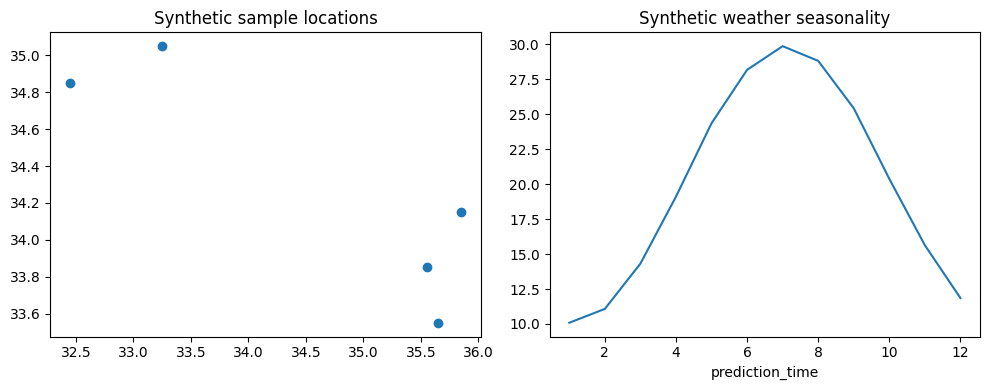

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10,4))
cells=tables['cells']
axes[0].scatter(cells.lon, cells.lat); axes[0].set_title('Synthetic sample locations')
tables['weather'].groupby(tables['weather'].prediction_time.dt.month).temperature_c.mean().plot(ax=axes[1], title='Synthetic weather seasonality')
plt.tight_layout()

Use `firecast sources` to refresh access checks. No real training region is approved. Build pre-test subregion profiles described in sources.md and call compare_profiles before admitting regional_cells.